In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import numpy as np

In [2]:
df= pd.read_csv("penguins_size.csv")
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [4]:
df["species"].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

In [5]:
df["island"].value_counts()

island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

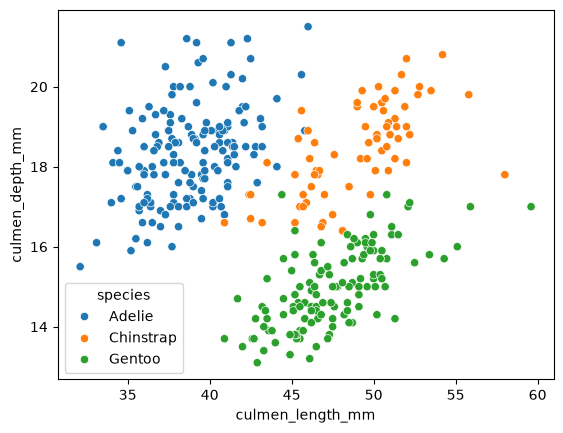

In [6]:
sns.scatterplot(x=df["culmen_length_mm"], y=df["culmen_depth_mm"], hue=df["species"])
plt.show()

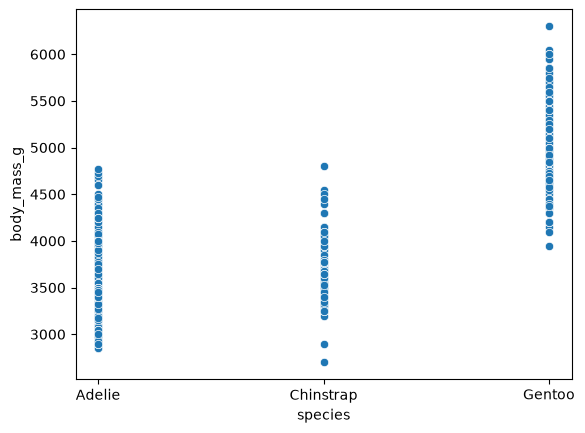

In [7]:
sns.scatterplot(y=df["body_mass_g"], x=df["species"])
plt.show()

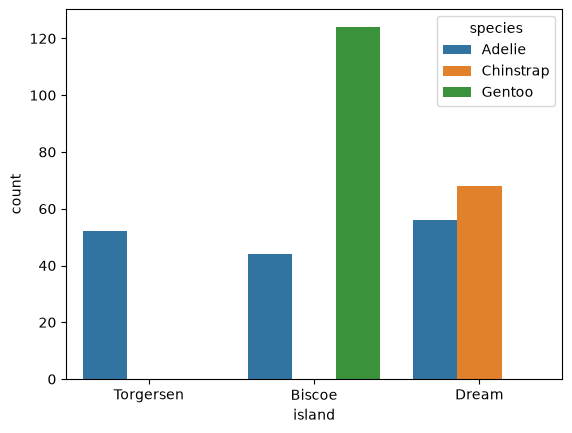

In [8]:
sns.countplot(x=df["island"], hue=df["species"])
plt.show()

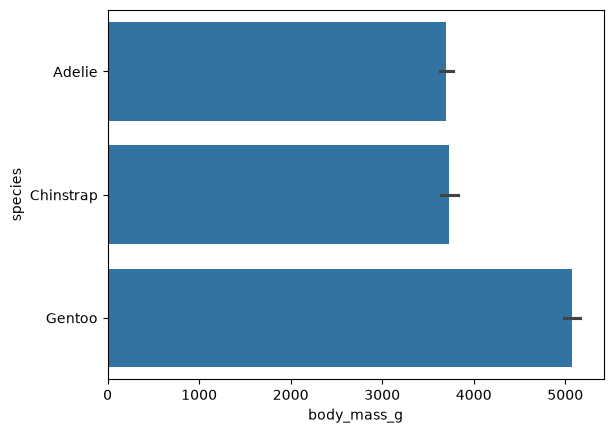

In [9]:
sns.barplot(x=df["body_mass_g"], y=df["species"])
plt.show()

In [10]:
df[df.isnull().any(axis=1)]

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


In [11]:
df.dropna(inplace=True)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 334 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            334 non-null    object 
 1   island             334 non-null    object 
 2   culmen_length_mm   334 non-null    float64
 3   culmen_depth_mm    334 non-null    float64
 4   flipper_length_mm  334 non-null    float64
 5   body_mass_g        334 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 20.9+ KB


In [13]:
df["sex"].value_counts()

sex
MALE      168
FEMALE    165
.           1
Name: count, dtype: int64

In [14]:
df.drop(df[df["sex"]=="."].index, inplace=True)

In [15]:
df["sex"].value_counts()

sex
MALE      168
FEMALE    165
Name: count, dtype: int64

In [16]:
one_hot= ["island", "sex"]
label_encode= ["species"]
standart_scaler= df.select_dtypes(include=["float64"]).columns.tolist()

In [17]:
standart_scaler

['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']

In [18]:
X=df.drop("species", axis=1)
y=df["species"]

In [19]:
from sklearn.preprocessing import LabelEncoder ,StandardScaler, OneHotEncoder

In [20]:
from sklearn.compose import ColumnTransformer

In [21]:
le=LabelEncoder()
pre_processing= ColumnTransformer(
    transformers=[
        ("num_col", StandardScaler(), standart_scaler),
        ("one_hot", OneHotEncoder(drop="if_binary", sparse_output=False), one_hot)
    ],
       remainder="passthrough")

y=le.fit_transform(df["species"])

In [22]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,

In [23]:
from sklearn.model_selection import train_test_split

In [24]:
X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [25]:
X_train= pre_processing.fit_transform(X_train)
X_test= pre_processing.transform(X_test)

In [26]:
X_train.shape

(266, 8)

In [27]:
X_train= torch.tensor(X_train, dtype=torch.float32)
X_test= torch.tensor(X_test, dtype= torch.float32)

y_train= torch.tensor(y_train, dtype= torch.long)
y_test= torch.tensor(y_test, dtype= torch.long)

In [28]:
from torch import nn

In [29]:
class PenguinClassifier(nn.Module):
    def __init__(self, in_features, hidden_units, out_features):
        super().__init__()

        self.linear_layer= nn.Sequential(
            nn.Linear(in_features=in_features, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=out_features)
        )

    def forward(self, x):
        return self.linear_layer(x)

In [30]:
torch.manual_seed(42)

model= PenguinClassifier(in_features=X_train.shape[1],
                         hidden_units=32,
                         out_features=len(le.classes_)
                        )

In [31]:
le.classes_

array(['Adelie', 'Chinstrap', 'Gentoo'], dtype=object)

In [32]:
model(X_train[:5])

tensor([[-0.2595,  0.0836, -0.0943],
        [-0.1165, -0.1154, -0.1446],
        [-0.1253,  0.0226, -0.0755],
        [-0.1128, -0.0301, -0.1107],
        [-0.1043, -0.1595, -0.1250]], grad_fn=<AddmmBackward0>)

In [33]:
loss_fn= nn.CrossEntropyLoss()
optimizer= torch.optim.Adam(params=model.parameters(), lr=0.01)

In [34]:
from torchmetrics.classification import MulticlassAccuracy

In [35]:
accuracy= MulticlassAccuracy(num_classes=3)

In [36]:
train_losses=[]
test_losses=[]

for epoch in range(100):
    model.train()
    logits=model(X_train)
    loss= loss_fn(logits, y_train)
    train_losses.append(loss.item())

    y_pred= torch.argmax(logits, dim=1)
    acc= accuracy(y_pred, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.inference_mode():

        test_logits= model(X_test)
        test_loss= loss_fn(test_logits, y_test)
        test_losses.append(test_loss.item())
        y_test_pred= torch.argmax(test_logits, dim=1)
        test_acc= accuracy(y_test_pred, y_test)

    if epoch % 5 == 0:
        print(f"Epoch:{epoch}, Loss:{loss.item()}, Accuracy:{acc.item()}, Test Loss:{test_loss.item()}, Test Accuracy:{test_acc.item()}")

Epoch:0, Loss:1.1161458492279053, Accuracy:0.14007598161697388, Test Loss:1.0431435108184814, Test Accuracy:0.6206896305084229
Epoch:5, Loss:0.7006843686103821, Accuracy:0.7749288082122803, Test Loss:0.6183286905288696, Test Accuracy:0.7742199897766113
Epoch:10, Loss:0.2861478626728058, Accuracy:0.8703703880310059, Test Loss:0.26175037026405334, Test Accuracy:0.8571429252624512
Epoch:15, Loss:0.10538379102945328, Accuracy:0.9662867784500122, Test Loss:0.08392373472452164, Test Accuracy:0.976190447807312
Epoch:20, Loss:0.04188108816742897, Accuracy:0.9881291389465332, Test Loss:0.025702444836497307, Test Accuracy:1.0
Epoch:25, Loss:0.015590931288897991, Accuracy:0.993827223777771, Test Loss:0.010382577776908875, Test Accuracy:1.0
Epoch:30, Loss:0.007351537235081196, Accuracy:1.0, Test Loss:0.015154639258980751, Test Accuracy:0.9885057210922241
Epoch:35, Loss:0.00483799260109663, Accuracy:1.0, Test Loss:0.009502844884991646, Test Accuracy:1.0
Epoch:40, Loss:0.0036680654156953096, Accurac

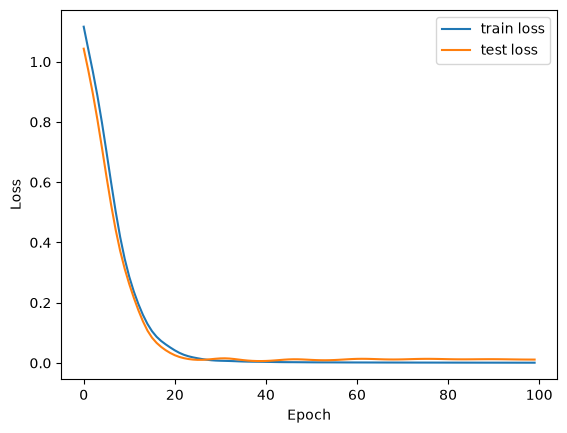

In [37]:
plt.plot(train_losses, label="train loss")
plt.plot(test_losses, label="test loss")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend()
plt.show()

In [38]:
from torchmetrics.classification import MulticlassConfusionMatrix

In [39]:
mc= MulticlassConfusionMatrix(num_classes=3)

In [40]:
logits=model(X_test)
y_ppred= torch.argmax(logits, dim=1)
matrix= mc(y_ppred, y_test)

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Predicted class', ylabel='True class'>)

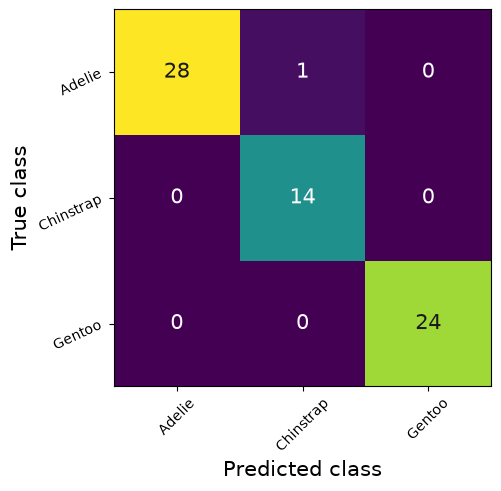

In [41]:
mc.plot(matrix, labels= le.classes_.tolist())

In [42]:
from pathlib import Path

In [43]:
MODEL_PATH= Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)
MODEL_NAME="penguin_classification.pth"
MODEL_SAVE_PATH= MODEL_PATH / MODEL_NAME
print(MODEL_SAVE_PATH)

models\penguin_classification.pth


In [44]:
torch.save(obj=model.state_dict(), f=MODEL_SAVE_PATH)

In [45]:
model_dic= {"in_features" : X_train.shape[1],
            "hidden_units" : 32,
            "out_features" : len(le.classes_)}

loaded_model= PenguinClassifier(**model_dic)

In [46]:
torch.load(MODEL_SAVE_PATH)

OrderedDict([('linear_layer.0.weight',
              tensor([[ 5.4730e-01,  5.4868e-02,  8.5345e-02,  3.9325e-01,  9.7841e-02,
                        3.0988e-01, -4.1716e-01,  1.4131e-01],
                      [ 4.0459e-01, -3.5611e-01,  3.8500e-01,  1.3474e-01,  3.5342e-01,
                        2.7919e-01,  4.5125e-02,  2.1447e-02],
                      [ 6.3591e-01, -2.7168e-01, -9.0812e-02,  1.5562e-02,  6.4067e-04,
                        2.4490e-01, -3.0799e-01,  1.8826e-01],
                      [-3.2643e-01, -2.9501e-01, -6.5970e-02, -1.5465e-01,  1.0968e-01,
                       -3.7375e-01,  2.6295e-01, -3.9107e-01],
                      [ 5.7263e-01, -6.3130e-02, -2.6413e-01, -9.1622e-02, -1.2089e-01,
                        4.4669e-01, -2.1883e-01, -4.5818e-01],
                      [ 2.4621e-01, -3.3238e-01,  3.5041e-01,  5.0950e-01,  4.1375e-01,
                       -3.9673e-01,  3.3307e-02,  1.9867e-01],
                      [-6.3172e-02,  1.0737e-02, -5.591

In [47]:
loaded_model.load_state_dict(torch.load(MODEL_SAVE_PATH))

<All keys matched successfully>

In [48]:
import joblib

In [52]:
joblib.dump(le, MODEL_PATH / "label_encoder.joblib")
joblib.dump(pre_processing, MODEL_PATH / "preprocessor.joblib")
joblib.dump(model_dic, MODEL_PATH / "model_config.joblib")

['models\\model_config.joblib']